# Progetto: Cross-Selling di Polizze Assicurative

### di Lavinia Solimani

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, confusion_matrix, classification_report, RocCurveDisplay, roc_auc_score

In [38]:
plt.rcParams['figure.figsize'] = (10, 6)
sns.set_theme(style = 'whitegrid')
RANDOM_SEED = 0

In [39]:
!wget https://proai-datasets.s3.eu-west-3.amazonaws.com/insurance_cross_sell.csv

--2026-06-14 14:56:06--  https://proai-datasets.s3.eu-west-3.amazonaws.com/insurance_cross_sell.csv
Resolving proai-datasets.s3.eu-west-3.amazonaws.com (proai-datasets.s3.eu-west-3.amazonaws.com)... 3.5.204.248, 3.5.205.248
Connecting to proai-datasets.s3.eu-west-3.amazonaws.com (proai-datasets.s3.eu-west-3.amazonaws.com)|3.5.204.248|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 21432357 (20M) [text/csv]
Saving to: ‘insurance_cross_sell.csv.3’

insurance_cross_sel 100%[===================>]  20.44M  12.0MB/s    in 1.7s    

2026-06-14 14:56:09 (12.0 MB/s) - ‘insurance_cross_sell.csv.3’ saved [21432357/21432357]



In [40]:
df = pd.read_csv('insurance_cross_sell.csv', index_col = 0)
df.head()

,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
id,,,,,,,,,,,
1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


## 1. Esplorazione del Dataset

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 381109 entries, 1 to 381109
Data columns (total 11 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Gender                381109 non-null  object 
 1   Age                   381109 non-null  int64  
 2   Driving_License       381109 non-null  int64  
 3   Region_Code           381109 non-null  float64
 4   Previously_Insured    381109 non-null  int64  
 5   Vehicle_Age           381109 non-null  object 
 6   Vehicle_Damage        381109 non-null  object 
 7   Annual_Premium        381109 non-null  float64
 8   Policy_Sales_Channel  381109 non-null  float64
 9   Vintage               381109 non-null  int64  
 10  Response              381109 non-null  int64  
dtypes: float64(3), int64(5), object(3)
memory usage: 34.9+ MB


Il dataset è costituito da 381.109 osservazioni per 10 features e 1 target. Non sono risultano valori mancanti.

Vediamo le statistiche di sintesi della variabile target *Response*.

In [42]:
df['Response'].describe()

,Response
count,381109.000000
mean,0.122563
std,0.327936
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,1.000000


Poiché la variabile target *Response* è una dummy che può assumere valori 0 o 1, il fatto che la media sia 0.12 lascia intendere che ci sia uno sbilanciamento all'interno del dataset di valori 0, ovvero di clienti che hanno rifiutato l'offerta di cross-selling.

Analizziamo la distribuzione della variabile per verificare questa ipotesi.

In [43]:
response_summary = pd.DataFrame({
    'Count': df['Response'].value_counts(),
    'Percentage (%)': (df['Response'].value_counts(normalize = True)*100).round(1)
})

print(response_summary)

           Count  Percentage (%)
Response                        
0         334399            87.7
1          46710            12.3


Si conferma, quindi, un netto sbilanciamento nel dataset, con una presenza di clienti che hanno rifiutato l'offerta di cross-selling molto maggiore rispetto ai clienti che hanno accettato. Per poter costruire un modello predittivo efficace, dovremo prima risolvere questo problema.

Procediamo con l'analisi della correlazione tra le varie features e la variabile target, per poter effettuare una feature selection ed eventualmente escludere dal modello le variabili non necessarie.

Prima, però, occorre mappare i valori delle variabili *Gender*, *Vehicle_Age* e *Vehicle_Damage* con valori numerici.

In [44]:
df['Gender'] = df['Gender'].map({'Male' : 1, 'Female' : 0})
df['Vehicle_Age'] = df['Vehicle_Age'].map({'< 1 Year' : 0, '1-2 Year' : 1, '> 2 Years' : 2})
df['Vehicle_Damage'] = df['Vehicle_Damage'].map({'No' : 0, 'Yes' : 1})

df.head()

,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
id,,,,,,,,,,,
1,1,44,1,28.0,0,2,1,40454.0,26.0,217,1
2,1,76,1,3.0,0,1,0,33536.0,26.0,183,0
3,1,47,1,28.0,0,2,1,38294.0,26.0,27,1
4,1,21,1,11.0,1,0,0,28619.0,152.0,203,0
5,0,29,1,41.0,1,0,0,27496.0,152.0,39,0


Ora che l'intero dataset è codificato, vediamo le statistiche di sintesi di tutte le variabili.

In [45]:
df.describe()

,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
count,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000
mean,0.540761,38.822584,0.997869,26.388807,0.458210,0.609616,0.504877,30564.389581,112.034295,154.347397,0.122563
std,0.498336,15.511611,0.046110,13.229888,0.498251,0.567439,0.499977,17213.155057,54.203995,83.671304,0.327936
min,0.000000,20.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2630.000000,1.000000,10.000000,0.000000
25%,0.000000,25.000000,1.000000,15.000000,0.000000,0.000000,0.000000,24405.000000,29.000000,82.000000,0.000000
50%,1.000000,36.000000,1.000000,28.000000,0.000000,1.000000,1.000000,31669.000000,133.000000,154.000000,0.000000
75%,1.000000,49.000000,1.000000,35.000000,1.000000,1.000000,1.000000,39400.000000,152.000000,227.000000,0.000000
max,1.000000,85.000000,1.000000,52.000000,1.000000,2.000000,1.000000,540165.000000,163.000000,299.000000,1.000000


Osservando i valori medi, possiamo fare queste considerazioni:

*   La media di *Gender* è di circa 0.54, indicando che il dataset è leggermente sbilanciato nella composizione, con più uomini (= 1) rispetto a donne (= 0).
*   L'età media dei clienti è di circa 39 anni.
*   Quasi la totalità dei clienti ha la patente di guida.
*   La media di *Previously_Insured* è di circa 0.46, indicando che il dataset è leggermente sbilanciato verso i clienti che non hanno già un veicolo assicurato (= 0) rispetto ai clienti che ce l'hanno (= 1).
*   La media di *Vehicle_Age* è di circa 0.61, indicando che la maggior parte dei clienti nel dataset hanno un veicolo che ha meno di 2 anni.
*   La media di *Vehicle_Damage* è di circa 0.5, indicando un quasi perfetto bilanciamento tra clienti che non hanno subito alcun incidente o danno al veicolo in passato (= 0) e clienti che l'hanno subito (= 1).
*   La media del premio assicurativo annuale è di circa 30564.
*   Il numero di giorni medio da cui i clienti di questo dataset sono assicurati con AssurePredict è circa 154.

Ora procediamo con l'analisi della correlazione tra le features e il target, rappresentandola graficamente tramite heatmap.

Poiché le features *Region_Code* e *Policy_Sales_Channel* sono in realtà variabili categoriche su scala nominale, non verranno incluse nella matrice di correlazione, bensì verranno analizzate differentemente.

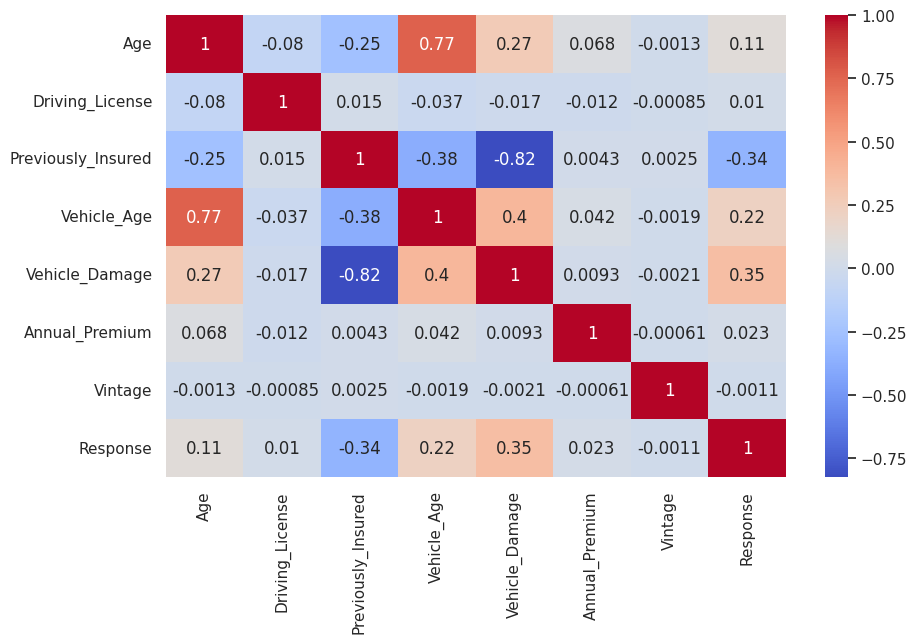

In [46]:
numerical_features = df[['Age', 'Driving_License', 'Previously_Insured', 'Vehicle_Age', 'Vehicle_Damage', 'Annual_Premium', 'Vintage', 'Response']]
sns.heatmap(numerical_features.corr(),
            annot = True,
            annot_kws = {'size':12},
            cmap = 'coolwarm')
plt.show()

Osservando innanzitutto la variabile target *Response*, si può constatare una maggiore correlazione con le seguenti features:

*   *Vehicle_Damage* (correlazione positiva, $r = 0.35$)
*   *Vehicle_Age* (correlazione positiva, $r = 0.22$)
*   *Age* (correlazione positiva, $r = 0.11$)
*   *Previously_Insured* (correlazione negativa, $r = -0.34$)

Pertanto, le features più significative per una previsione della risposta a un'offerta di cross-selling risultano essere un precedente incidente o danno al veicolo del cliente, e se il cliente ha già un veicolo assicurato o meno. In particolare, i clienti che hanno subito un danno al veicolo sono più propensi ad accettare l'offerta di cross-selling, mentre i clienti che hanno già un veicolo assicurato sono più propensi a rifiutare.
Infine, la correlazione positiva dell'età del veicolo e l'età del cliente con *Response* indica che, più è avanzata l'età del cliente e quella del veicolo, maggiore sarà la propensione ad accettare l'offerta di cross-selling.


Ora, invece, esploriamo le correlazioni più significative tra features, che possono rivelare un problema di multicollinearità nel dataset:

*   *Vehicle_Damage* e *Previously_Insured* presentano la correlazione maggiormente negativa di tutto il dataset, con $r = -0.82$, indicando che i clienti che erano precedentemente assicurati per il proprio veicolo tendono a non aver avuto incidenti o danni al veicolo, e viceversa. Anche *Vehicle_Age* mostra una moderata correlazione negativa con *Previously_Insured* ($r = -0.38$).
*   *Vehicle_Age* e *Age* presentano la correlazione maggiormente positiva di tutto il dataset, con $r = 0.77$. Ciò significa che i clienti più anziani tendono ad avere un veicolo meno recente.

Ora esploriamo la relazione tra il target e le features *Region_Code* e *Policy_Sales_Channel*.

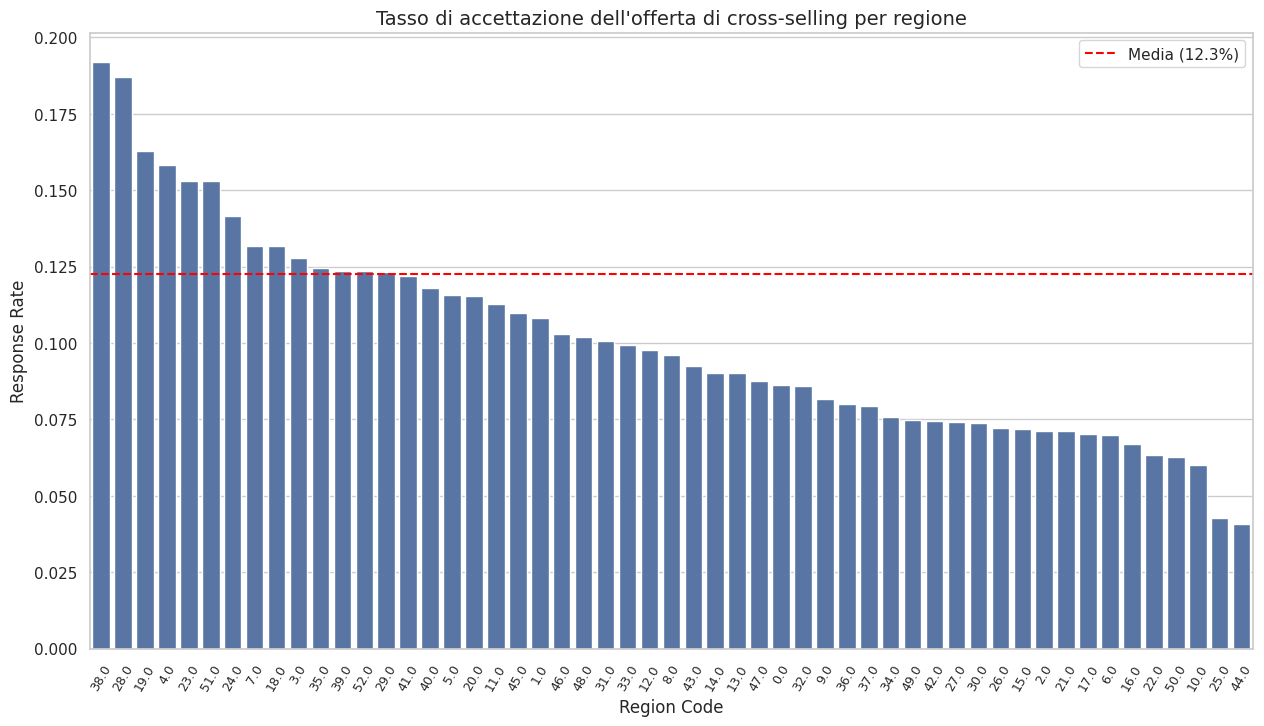

In [47]:
region_stats = df.groupby('Region_Code')['Response'].agg(['count', 'mean']).reset_index()
region_stats.columns = ['Region Code', 'Count', 'Response Rate']
region_stats = region_stats.sort_values(by = 'Response Rate', ascending = False)

plt.figure(figsize = (15, 8))
sns.barplot(data = region_stats,
            x = 'Region Code',
            y = 'Response Rate',
            order = region_stats['Region Code'])
plt.axhline(df['Response'].mean(),
            c = 'red',
            linestyle = '--',
            label = f'Media ({df['Response'].mean()*100:.1f}%)')
plt.title('Tasso di accettazione dell\'offerta di cross-selling per regione', fontsize = 14)
plt.xticks(rotation = 60, fontsize = 9)
plt.legend()
plt.show()

Dal grafico si evince, quindi, che in circa 10 regioni il tasso di accettazione dell'offerta di cross-selling è sopra la media globale, fornendo una preziosa indicazione alla compagnia di assicurazioni relativamente a potenziali campagne di marketing locali mirate. In altre regioni, invece, il tasso di accettazione è molto inferiore alla media, indicando la necessità di rivalutare le strategie di marketing in quelle zone.

Ora riproponiamo questo grafico per la feature *Policy_Sales_Channel*, rappresentando però solamente i valori (ovvero, le codifiche dei canali) associati ad almeno 500 osservazioni.

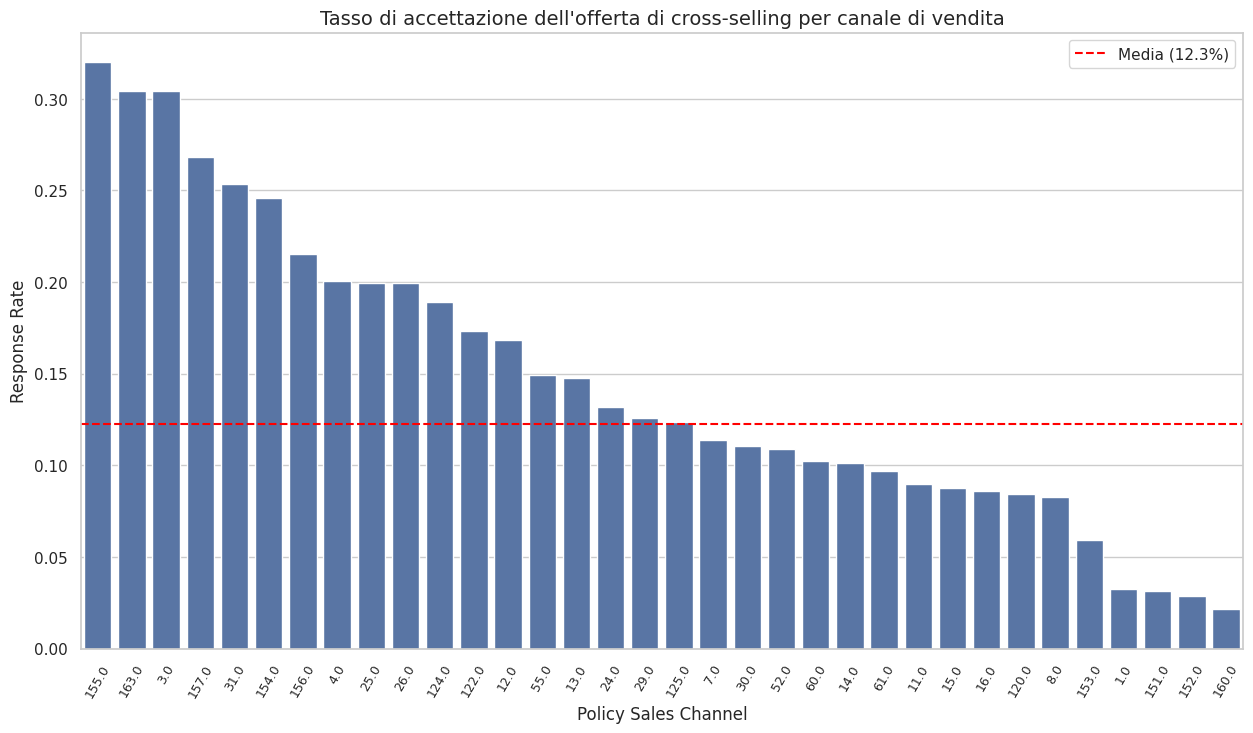

In [48]:
channel_stats = df.groupby('Policy_Sales_Channel')['Response'].agg(['count', 'mean']).reset_index()
channel_stats.columns = ['Policy Sales Channel', 'Count', 'Response Rate']
channel_stats_filtered = channel_stats[channel_stats['Count'] >= 500].sort_values(by = 'Response Rate', ascending = False)

plt.figure(figsize = (15, 8))
sns.barplot(data = channel_stats_filtered,
            x = 'Policy Sales Channel',
            y = 'Response Rate',
            order = channel_stats_filtered['Policy Sales Channel'])
plt.axhline(df['Response'].mean(),
            c = 'red',
            linestyle = '--',
            label = f'Media ({df['Response'].mean()*100:.1f}%)')
plt.title('Tasso di accettazione dell\'offerta di cross-selling per canale di vendita', fontsize = 14)
plt.xticks(rotation = 60, fontsize = 9)
plt.legend()
plt.show()

Anche in questo caso, si può notare una netta differenza nel tasso di accettazione dell'offerta di cross-selling in base al canale di vendita. Pertanto, questa feature fornisce informazioni preziose, ed è opportuno includerla nel modello predittivo.

## 2. Gestione dello Sbilanciamento delle Classi

Come abbiamo visto all'inizio dell'analisi, il dataset è fortemente sbilanciato nel caso della variabile target *Response*, con l'87,7% dei clienti che rifiutano l'offerta e solamente il 12,3% che l'accettano. Per gestire questo problema, applicheremo la tecnica del class weighting all'interno del modello predittivo, in modo da penalizzare la classe più frequente.

## 3. Costruzione del Modello Predittivo

Poiché stiamo gestendo una classificazione binaria, costruiremo un modello di regressione logistica.

A questo punto, si pone il problema di quali features includere nel modello predittivo. Infatti, *Vehicle_Damage* e *Previously_Insured* sono le features maggiormente correlate con il target, ma risultano anche fortemente correlate tra di loro, dando origine a un problema di multicollinearità. Pertanto, procederemo con due diverse soluzioni, per poi scegliere quella migliore:

1.   Un primo modello, dal quale rimuoveremo una di queste due features.
2.   Un secondo modello, nel quale manterremo entrambe le features, ma per il quale utilizzeremo una regressione Ridge. Come indicato nella relativa <[documentazione](https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression), infatti, questa tipologia di regressione applica una regolarizzazione L2 al modello, mediante la quale vengono associati dei pesi ai coefficienti e questi ultimi vengono penalizzati in base alla dimensione. Maggiore è il valore del parametro associato al peso, più il coefficiente diventerà più robusto nei confronti della collinearità.

Possiamo, invece, escludere in ogni caso dal modello le features che non presentano correlazione con la variabile target, quindi *Driving_License*, *Annual_Premium* e *Vintage*.

### 3.1 Primo modello

La feature che verrà rimossa dal modello è *Previously_Insured*, mentre lasceremo *Vehicle_Damage*.

In [49]:
X_1 = df.drop(['Driving_License', 'Previously_Insured', 'Annual_Premium', 'Vintage', 'Response'], axis = 1)
X_1.shape

(381109, 6)

In [50]:
y = df['Response']
y.shape

(381109,)

Ora definiamo gli array del set di addestramento e del set di test, dopodiché effettuiamo il Data Preprocessing per preparare i dati che verranno passati al modello.

Nello specifico, eseguiremo una standardizzazione delle variabili numeriche su scala ordinale, ovvero *Age* e *Vehicle_Age*, mentre eseguiremo il Target Encoding e successivamente la standardizzazione per le variabili numeriche su scala nominale, ovvero *Region_Code* e *Policy_Sales_Channel*. Come riportato in [questo articolo](https://letsdatascience.com/blog/categorical-encoding-a-practical-guide-to-one-hot-label-and-target-methods), infatti, il Target Encoding risulta essere la tecnica più adatta per gestire variabili ad alta cardinalità.

Per le variabili binarie, invece, ovvero *Gender* e *Vehicle_Damage*, non applicheremo alcuna trasformazione.

Per snellire il codice, inseriamo il metodo **Pipeline()** all'interno di **ColumnTransformer()**, poiché ci permette di applicare dei trasformatori ai dati sequenzialmente, come indicato nella relativa [documentazione](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html#sklearn.pipeline.Pipeline).

In [51]:
X_1_train, X_1_test, y_1_train, y_1_test = train_test_split(X_1,
                                                            y,
                                                            test_size = .3,
                                                            random_state = RANDOM_SEED,
                                                            stratify = y)

ordinal_features = ['Age', 'Vehicle_Age']
nominal_features = ['Region_Code', 'Policy_Sales_Channel']

In [52]:
data_preprocessor = ColumnTransformer(
    [
        ('ordinal', Pipeline(
            [
                ('scale', StandardScaler())
            ]
            ), ordinal_features),

        ('nominal', Pipeline(
            [
                ('encoder', TargetEncoder(smooth = 'auto', cv = 5, random_state = RANDOM_SEED)),
                ('scaler', StandardScaler())
            ]
            ), nominal_features)
    ],
    remainder = 'passthrough'
)

X_1_train = data_preprocessor.fit_transform(X_1_train, y_1_train)
X_1_test = data_preprocessor.transform(X_1_test)

Ora possiamo istanziare la classe e addestrare il modello di regressione logistica sul set di addestramento. Poiché le due classi sono sbilanciate, assegniamo un peso in proporzione alla frequenza della classe all'interno del dataset, in modo da penalizzare la classe più frequente.

In [53]:
log_regr_1 = LogisticRegression(class_weight = 'balanced', max_iter = 1000)
log_regr_1.fit(X_1_train, y_1_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

Definiamo ora una funzione per la valutazione del modello predittivo.

In [54]:
def evaluate_model(model, dataset):

  X, y = dataset

  y_pred = model.predict(X)
  y_proba = model.predict_proba(X)

  print(classification_report(y, y_pred))
  print(f'Log Loss: {log_loss(y, y_proba):.3f}')
  print(f'ROC AUC score: {roc_auc_score(y, y_proba[:, 1], multi_class = 'ovo', average = 'macro'):.3f}')

In [55]:
evaluate_model(log_regr_1, (X_1_train, y_1_train))

              precision    recall  f1-score   support

           0       0.98      0.67      0.79    234079
           1       0.27      0.90      0.42     32697

    accuracy                           0.70    266776
   macro avg       0.63      0.78      0.61    266776
weighted avg       0.89      0.70      0.75    266776

Log Loss: 0.497
ROC AUC score: 0.832


In [56]:
evaluate_model(log_regr_1, (X_1_test, y_1_test))

              precision    recall  f1-score   support

           0       0.98      0.67      0.80    100320
           1       0.27      0.90      0.42     14013

    accuracy                           0.70    114333
   macro avg       0.63      0.78      0.61    114333
weighted avg       0.89      0.70      0.75    114333

Log Loss: 0.496
ROC AUC score: 0.832


Esaminiamo i risultati della valutazione più nel dettaglio.

1.   La Log Loss è di 0.497 nel set di addestramento e di 0.498 nel set di test, quindi il valore rimane pressoché identico.
2.   Il ROC AUC score è di 0.832 per il set di addestramento e di 0.833 per il set di test; un ottimo risultato, considerato che un valore di 1 indica un modello predittivo perfetto.
3.   Le altre metriche (Accuracy, Precision, Recall e F1 Score) rimangono pressoché identiche tra i due set.

Il fatto che le performance del modello rimangano invariate tra il set di addestramento e il set di test ci fa escludere, pertanto, una problematica di overfitting.

Rimane opportuno evidenziare che, mentre alcune metriche sono molto soddisfacenti, altre sono migliorabili. Ad esempio, una sensibilità di 0.90 significa che il modello riesce ad identificare correttamente il 90% dei clienti che accettano l'offerta, una precisione di 0.28 indica che, rispetto al totale di clienti che il modello identifica come quelli che accettano l'offerta, solamente il 28% rientra effettivamente in quella categoria. In altre parole, abbiamo una percentuale del 72% di falsi positivi.

In [57]:
y_1_pred_train = log_regr_1.predict(X_1_train)
y_1_pred_test = log_regr_1.predict(X_1_test)

Visualizziamo ora la matrice di confusione sia per il set di addestramento che per il set di test.

In [58]:
def plot_confusion_matrix(y_true, y_pred, labels = ['Rejected', 'Accepted'], show_precision_recall = False):

  cm = confusion_matrix(y_true, y_pred)

  df_cm = pd.DataFrame(cm,
                       index = labels,
                       columns = ['Predicted '+labels[0], 'Predicted '+labels[1]])

  sns.heatmap(df_cm, annot = True, fmt = 'g')

  if show_precision_recall:
    plt.text(0, -0.1, f'Precision: {cm[1][1] / (cm[1][1]+cm[0][1]):.3f}')
    plt.text(1, -0.1, f'Recall: {cm[1][1] / (cm[1][1]+cm[1][0]):.3f}')

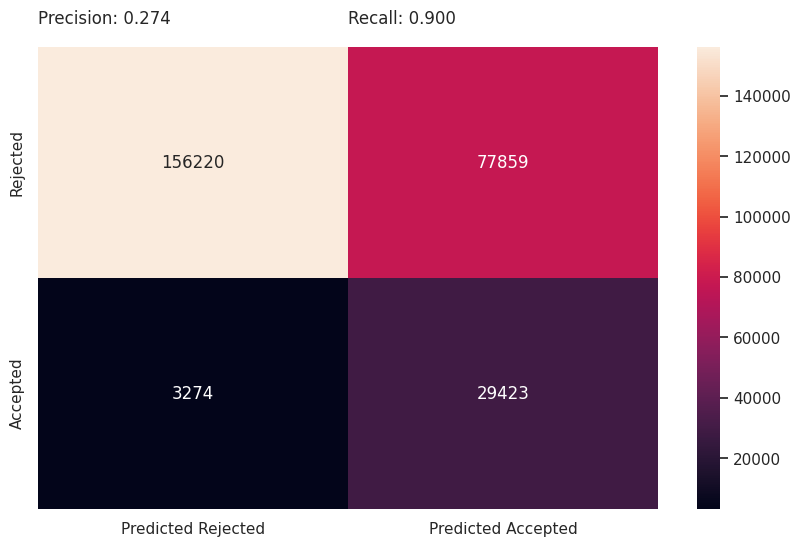

In [59]:
plot_confusion_matrix(y_1_train, y_1_pred_train, show_precision_recall = True)

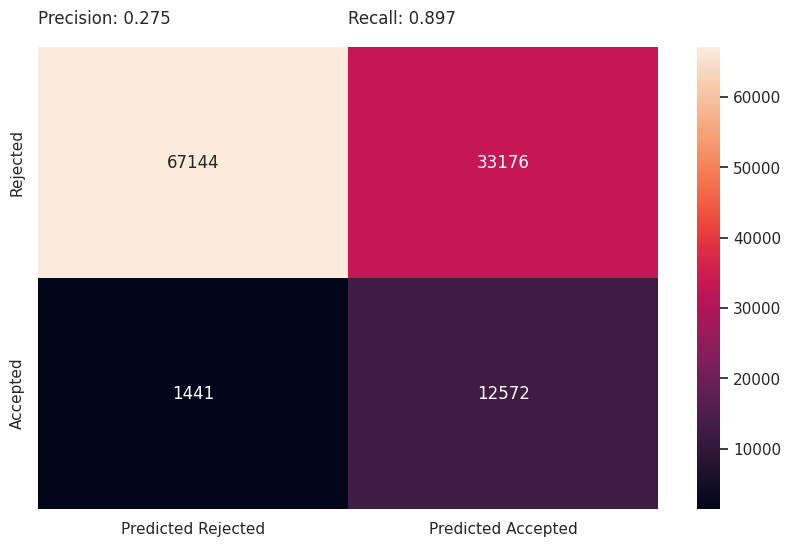

In [60]:
plot_confusion_matrix(y_1_test, y_1_pred_test, show_precision_recall = True)

La bassa precisione del modello si nota soffermandosi sulla cella in alto a destra, dove è riportato il numero di clienti che il modello prevede che abbiano accettato l'offerta quando, in realtà, l'hanno rifiutata.

Per provare a ridurre la percentuale di falsi positivi, possiamo portare il threshold a, per esempio, 0.75.

In [61]:
y_1_proba_train_v2 = log_regr_1.predict_proba(X_1_train)
y_1_proba_test_v2 = log_regr_1.predict_proba(X_1_test)

y_1_pred_train_v2 = np.where(y_1_proba_train_v2[:, 1] > 0.75, 1, 0)
y_1_pred_test_v2 = np.where(y_1_proba_test_v2[:, 1] > 0.75, 1, 0)

print(f'TRAIN SET:\n {classification_report(y_1_train, y_1_pred_train_v2)}\n')
print(f'TEST SET:\n {classification_report(y_1_test, y_1_pred_test_v2)}')

TRAIN SET:
               precision    recall  f1-score   support

           0       0.91      0.89      0.90    234079
           1       0.33      0.39      0.36     32697

    accuracy                           0.83    266776
   macro avg       0.62      0.64      0.63    266776
weighted avg       0.84      0.83      0.83    266776


TEST SET:
               precision    recall  f1-score   support

           0       0.91      0.89      0.90    100320
           1       0.33      0.39      0.36     14013

    accuracy                           0.83    114333
   macro avg       0.62      0.64      0.63    114333
weighted avg       0.84      0.83      0.83    114333



Possiamo constatare che, pur essendo incrementata la precisione (0.33 in entrambi i set), la sensibilità è diminuita drasticamente, con un valore di 0.39 nel set di addestramento e di 0.40 nel set di test.

Il modello, quindi, ritorna delle performance migliori se il dataset rimane bilanciato tramite l'argomento **class_weight**.

Come ultima metrica, visualizziamo la ROC Curve, per verificare le performance del modello a diversi valori di threshold. Poiché il valore del ROC AUC Score è di 0.83 sia per il set di addestramento che per il set di test, la curva è identica per i due set.

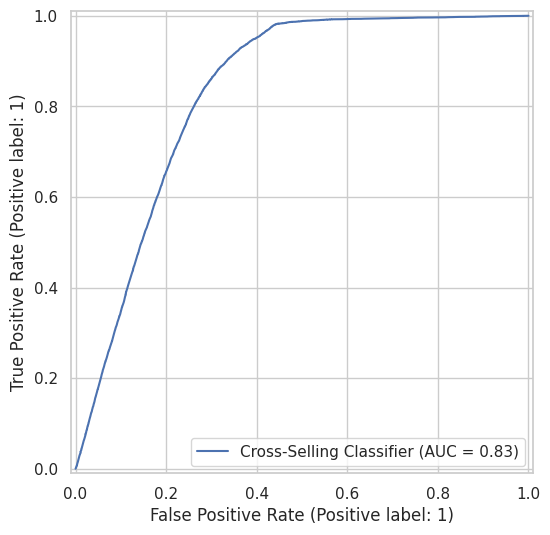

In [62]:
RocCurveDisplay.from_estimator(log_regr_1, X_1_test, y_1_test, name = 'Cross-Selling Classifier')
plt.show()

Il tradeoff, essenzialmente, è il seguente: intercettare più clienti possibili che accettano l'offerta, massimizzando la recall ma sacrificando la precisione (poiché aumenta sia il numero di veri positivi, che di falsi positivi), oppure affinare l'obiettivo e intercettare meno clienti, ma più mirati, migliorando quindi la precisione ma abbassando la recall (poiché diminuisce il numero di falsi positivi, ma anche di veri positivi).

### 3.2 Secondo modello

Ora costruiremo un nuovo modello, lasciando entrambe le feature *Previously_Insured* e *Vehicle_Damage* e applicando, invece, un modello di regressione Ridge.

In [63]:
X_2 = df.drop(['Driving_License', 'Annual_Premium', 'Vintage', 'Response'], axis = 1)
X_2.shape

(381109, 7)

In [64]:
"""
Split the dataset into train set and test set
"""
X_2_train, X_2_test, y_2_train, y_2_test = train_test_split(X_2,
                                                            y,
                                                            test_size = .3,
                                                            random_state = RANDOM_SEED,
                                                            stratify = y)

"""
Pre-process the data
"""
ordinal_features = ['Age', 'Vehicle_Age']
nominal_features = ['Region_Code', 'Policy_Sales_Channel']

data_preprocessor = ColumnTransformer(
    [
        ('ordinal', Pipeline(
            [
                ('scale', StandardScaler())
            ]
            ), ordinal_features),

        ('nominal', Pipeline(
            [
                ('encoder', TargetEncoder(smooth = 'auto', cv = 5, random_state = RANDOM_SEED)),
                ('scaler', StandardScaler())
            ]
            ), nominal_features)
    ],
    remainder = 'passthrough'
)

X_2_train = data_preprocessor.fit_transform(X_2_train, y_2_train)
X_2_test = data_preprocessor.transform(X_2_test)

Addestriamo il modello di regressione logistica, applicando però la regolarizzazione L2 (Ridge). Passiamo al suo interno anche l'argomento **C** con un valore di 0.1 poiché, minore è il valore, maggiore sarà l'intensità della regolarizzazione. Dato che il valore di default è 1.0, un valore di 0.1 implica una forte regolarizzazione.

In [65]:
log_regr_2 = LogisticRegression(penalty = 'l2',
                                C = 0.1,
                                class_weight = 'balanced',
                                random_state = RANDOM_SEED,
                                max_iter = 1000)
log_regr_2.fit(X_2_train, y_2_train)

LogisticRegression(C=0.1, class_weight='balanced', max_iter=1000,
                   random_state=0)

In [66]:
evaluate_model(log_regr_2, (X_2_train, y_2_train))

              precision    recall  f1-score   support

           0       0.99      0.65      0.78    234079
           1       0.27      0.93      0.42     32697

    accuracy                           0.68    266776
   macro avg       0.63      0.79      0.60    266776
weighted avg       0.90      0.68      0.74    266776

Log Loss: 0.480
ROC AUC score: 0.843


In [67]:
evaluate_model(log_regr_2, (X_2_test, y_2_test))

              precision    recall  f1-score   support

           0       0.99      0.65      0.78    100320
           1       0.27      0.93      0.42     14013

    accuracy                           0.69    114333
   macro avg       0.63      0.79      0.60    114333
weighted avg       0.90      0.69      0.74    114333

Log Loss: 0.478
ROC AUC score: 0.844


Esaminiamo i risultati della valutazione e paragoniamoli a quanto ottenuto dal primo modello.

1.   La Log Loss è di 0.480 nel set di addestramento e di 0.481 nel set di test, quindi i valori sono più bassi (ovvero migliori) rispetto al primo modello, dove la Log Loss era di 0.497 e 0.498.
2.   Il ROC AUC score è di 0.843 per il set di addestramento e di 0.844 per il set di test, quindi leggermente migliore rispetto al primo modello, per il quale il ROC AUC score era di 0.832 e 0.833.
3.   La precisione rimane identica tra i due modelli, mentre aumenta la sensibilità (recall), in quanto passa da 0.90 nel primo modello a 0.93 e 0.94 nel secondo. Ciò significa che vengono correttamente classificati come positivi il 93% e il 94% dei clienti che danno una risposta positiva, ovvero che accettano la proposta di cross-selling. L'F1 Score, invece, rimane a 0.42 in entrambi i modelli, mentre l'accuracy incrementa di due punti percentuali, passando da 0.68 a 0.70.

Anche in questo secondo modello possiamo escludere la presenza di overfitting, dato che le performance rimangono invariate passando dal set di addestramento al set di test.

In [68]:
y_2_pred_train = log_regr_2.predict(X_2_train)
y_2_pred_test = log_regr_2.predict(X_2_test)

Visualizziamo la matrice di confusione anche per il set di addestramento e il set di test del secondo modello.

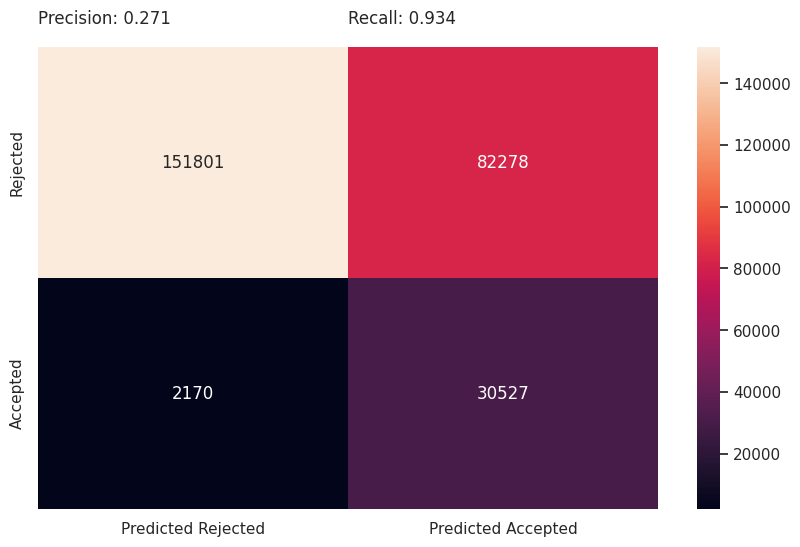

In [69]:
plot_confusion_matrix(y_2_train, y_2_pred_train, show_precision_recall = True)

Notiamo che la precisione è effettivamente diminuita, anche se di molto poco; questa diminuzione da 0.274 a 0.269 si riscontra nella cella in alto a destra, poiché il numero di clienti classificati come accettanti l'offerta, ma che in realtà la rifiutano, sono 82.715 nel secondo modello, contro i 77.625 del primo modello.

Allo stesso tempo, si nota che la recall è passata da 0.898 nel primo modello a 0.934 nel secondo modello. Si può vedere, infatti, che il numero di clienti accettanti l'offerta, che sono stati correttamente classificati, sono passati da 29.295 nel primo modello a 30.467 nel secondo modello.

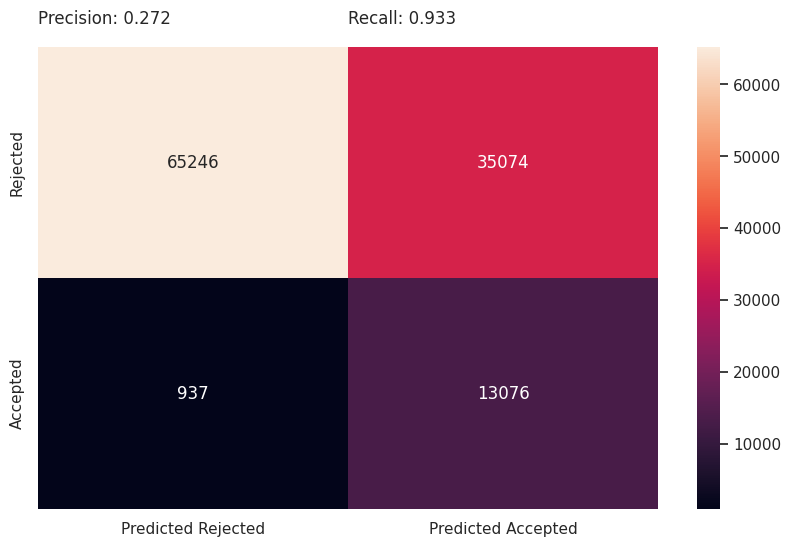

In [70]:
plot_confusion_matrix(y_2_test, y_2_pred_test, show_precision_recall = True)

I set di test dei due modelli si comportano in maniera molto simile. La precisione diminuisce da 0.275 a 0.271, ed è dimostrato dall'aumento dei clienti erroneamente classificati come accettanti l'offerta (da 33.353 nel primo modello a 35.533 nel secondo), mentre la recall aumenta da 0.900 a 0.937, ed è dimostrato dall'aumento di clienti correttamente classificati come accettanti l'offerta (da 12.680 nel primo modello a 13.201 nel secondo).

Visualizziamo infine l'ultima metrica, ovvero la ROC Curve. Poiché il ROC AUC Score del secondo modello è di 0.84, rispetto a 0.83 del primo modello, la curva è quasi identica per i due modelli.

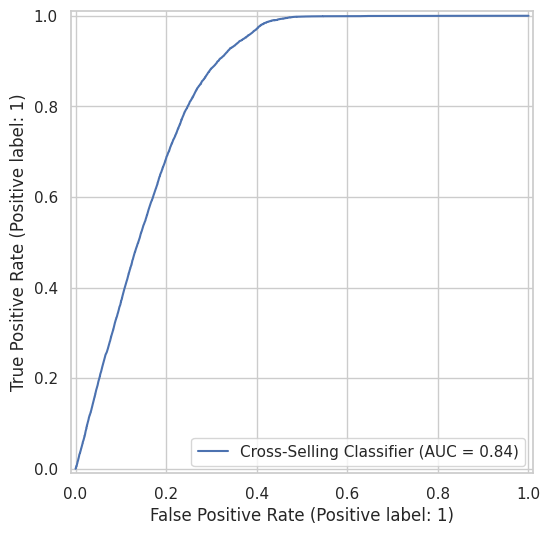

In [71]:
RocCurveDisplay.from_estimator(log_regr_2, X_2_test, y_2_test, name = 'Cross-Selling Classifier')
plt.show()

## Conclusione

Considerato che il secondo modello ha un ROC AUC Score maggiore, anche se di poco, e che anche le altre metriche sono leggermente migliori rispetto al primo modello, la scelta finale ricade sul secondo modello.

Sulla base dei risultati delle previsioni, vale la pena fare le seguenti considerazioni.

*   Il modello predittivo ha un'elevata recall, perciò permette di intercettare e classificare correttamente la maggior parte dei clienti propensi ad acquistare la polizza auto, con un conseguente aumento del tasso di conversione nelle vendite e un miglioramento dei profitti.
*   L'accuracy si attesta a 0.68, indicando che il 68% delle previsioni sono corrette.
*   Allo stesso tempo, però, il modello presenta una bassa precisione, portando così a un'errata identificazione di molti clienti come potenzialmente interessati alla polizza auto quando, invece, non lo sono.

In base a quanto sopra, l'agenzia assicurativa potrebbe optare per campagne di marketing più automatizzate, approcciando quindi i clienti in maniera più rapida e meno dispendiosa. Un esempio potrebbe essere quello di mandare una mail ai clienti per pubblicizzare l'offerta di cross-selling, anziché telefonare. Approcci di questo tipo sarebbero più rapidi e meno dispendiosi, e possono quindi essere utilizzati su un numero molto ampio di clienti senza incorrere in costi troppo elevati.